## Section 0 - Setup

In [22]:
import warnings, pickle, ast, os, re, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
NAVY, TEAL, GREY, RED, AMBER = "#0B2545", "#13A89E", "#8D99AE", "#D62839", "#F4A261"

ROOT = Path("..")
MASTER_CSV = ROOT/"data_processed"/"metro_trips_clean.csv"
MODEL_CSV  = ROOT/"data_processed"/"metro_trips_model_ready.csv"
SARIMA_CSV = ROOT/"docs"/"sarima_results_final.csv"
LSTM_CSV   = ROOT/"docs"/"lstm_results_summary.csv"
SARIMA_DIR, LSTM_DIR = ROOT/"models"/"sarima", ROOT/"models"/"lstm"
APP_PY = ROOT/"dashboard"/"app.py"                     
OUT = ROOT/"docs"/"testing"; FIG, TAB, SHOTS = OUT/"figures", OUT/"tables", OUT/"screenshots"
for p in (FIG, TAB, SHOTS): p.mkdir(parents=True, exist_ok=True)
HOLDOUT, WINDOW = 6, 12

def save_fig(fig, label, slug):
    p = FIG/f"{label.replace(' ', '_')}_{slug}.png"; fig.savefig(p, bbox_inches="tight", facecolor="white"); print("saved", p); plt.show()
def save_table(df, label, slug):
    stem = TAB/f"{label.replace(' ', '_')}_{slug}"
    df.to_csv(str(stem) + ".csv", index=False); df.to_html(str(stem) + ".html", index=False); print("saved", stem.name); return df
def safe(name): return name.replace('/', '_').replace(' ', '_')
def mape(a, f): a, f = np.asarray(a, float), np.asarray(f, float); return float(np.mean(np.abs((a - f) / a)) * 100)
def rmse(a, f): a, f = np.asarray(a, float), np.asarray(f, float); return float(np.sqrt(np.mean((a - f) ** 2)))
def mae(a, f):  a, f = np.asarray(a, float), np.asarray(f, float); return float(np.mean(np.abs(a - f)))

master = pd.read_csv(MASTER_CSV, parse_dates=["date"])
model  = pd.read_csv(MODEL_CSV,  parse_dates=["date"]).sort_values(["metro_station", "date"])
sar, lst_all = pd.read_csv(SARIMA_CSV), pd.read_csv(LSTM_CSV)
lst = lst_all.dropna(subset=["MAPE_lstm"]).reset_index(drop=True)
comp = sar[["station","order","seasonal_order","MAPE_sarima","RMSE_sarima","MAE_sarima","interpolated_months"]].merge(
        lst[["station","MAPE_lstm","RMSE_lstm","MAE_lstm","std_across_runs"]], on="station", how="outer")
comp["winner"] = np.where(comp.MAPE_lstm.isna(), "SARIMA (LSTM insufficient data)", np.where(comp.MAPE_sarima < comp.MAPE_lstm, "SARIMA", "LSTM"))

def full_name(short):
    hits = [s for s in model.metro_station.unique() if short.lower() in s.lower()]
    assert len(hits) == 1, f"'{short}' matched {hits}"; return hits[0]
def get_series(name):
    s = model[model.metro_station == full_name(name)].set_index("date")["trips"].asfreq("MS")
    return s.interpolate("linear").bfill().ffill()
print("loaded:", len(master), "master rows;", len(model), "model-ready rows;", len(sar), "SARIMA rows;", len(lst), "LSTM rows")

loaded: 4889 master rows; 3405 model-ready rows; 53 SARIMA rows; 51 LSTM rows


## Section A - Automated tests (T01-T12) and Table 6.1

Each test returns `(ok, detail)`: `True`/`False` for pass/fail, `None` for *not run* (for example a missing file). Failures are shown, never hidden: a failing test is a finding to fix and then re-run, and the final status is what goes in Table 6.1.

In [23]:
results = []
def run_test(tid, req, desc, expected, fn):
    try: ok, detail = fn()
    except Exception as e: ok, detail = False, f"{type(e).__name__}: {e}"
    status = "Not run" if ok is None else ("Pass" if ok else "FAIL")
    results.append(dict(ID=tid, Requirement=req, Test=desc, Method="Automated", Expected=expected, Result=status, Evidence=detail))
    print(f"{status:8s} {tid}  {detail}")

# ---- T01: data integrity (also guards the 'unsorted rows' defect D05) ----
def t01():
    m = master.sort_values(["metro_station", "date"])
    ok_n = m.metro_station.nunique() == 53
    ok_dup = not m.duplicated(["metro_station", "date"]).any()
    ok_pos = (m.trips > 0).all()
    ok_sorted = master.groupby("metro_station").date.apply(lambda s: s.is_monotonic_increasing).all()
    return all([ok_n, ok_dup, ok_pos, ok_sorted]), f"53 stations={ok_n}; no duplicate station-month={ok_dup}; trips>0={ok_pos}; rows stored in date order={ok_sorted}"
run_test("T01", "Data", "Master file: 53 stations, one row per station-month, trips > 0, rows sorted", "All four conditions true", t01)

# ---- T02: validated window ----
def t02():
    ok = (len(model) == 3405) and (model.date.min() == pd.Timestamp("2018-01-01")) and (model.date.max() == pd.Timestamp("2023-08-01"))
    return ok, f"rows={len(model)} (expect 3,405); window {model.date.min().date()} to {model.date.max().date()}"
run_test("T02", "Data", "Model-ready file covers Jan 2018 - Aug 2023 with 3,405 rows", "3,405 rows; window as stated", t02)

# ---- T03: station-name consistency (guards the Burj Khalifa defect D06) ----
def t03():
    ms, ss, ls = set(model.metro_station), set(sar.station), set(lst.station)
    a = ms == ss; b = ls <= ms and len(ls) == 51
    return a and b, f"SARIMA names match data={a} (diff {sorted(ms ^ ss)[:3]}); LSTM names subset of data with 51 rows={b} (n={len(ls)})"
run_test("T03", "Data", "Station names identical across data and result files (53 / 51)", "Name sets match", t03)

# ---- T04 + T10: artefacts load; timing proxy for NFR1 ----
sarima_models, lstm_models, load_seconds = {}, {}, {}
def t04():
    import tensorflow as tf; from tensorflow.keras.models import load_model
    t0 = time.perf_counter()
    for st in sar.station:
        with open(SARIMA_DIR/f"{safe(st)}.pkl", "rb") as f: sarima_models[st] = pickle.load(f)
    load_seconds["sarima"] = time.perf_counter() - t0
    t1 = time.perf_counter()
    for st in lst.station:
        lstm_models[st] = load_model(LSTM_DIR/f"{safe(st)}.keras", compile=False)
    load_seconds["lstm"] = time.perf_counter() - t1
    ok = len(sarima_models) == 53 and len(lstm_models) == 51
    return ok, f"SARIMA loaded={len(sarima_models)}/53 in {load_seconds['sarima']:.2f}s; LSTM loaded={len(lstm_models)}/51 in {load_seconds['lstm']:.2f}s"
run_test("T04", "FR4, FR5", "All 53 SARIMA and 51 LSTM model artefacts load", "53 and 51 models load without error", t04)

def t10():
    tot = load_seconds["sarima"] + load_seconds["lstm"]
    return tot < 3, f"model loading total {tot:.2f}s (limit 3s). PROXY ONLY: confirm page load in the browser (Section C)"
run_test("T10", "NFR1", "Start-up model loading time below 3 s (proxy for page load)", "< 3 s", t10)

# ---- T05: forecasts valid for every station (horizon 12) ----
def t05():
    bad = []
    for st, fit in sarima_models.items():
        fc = np.asarray(fit.get_forecast(12).predicted_mean)
        if (not np.isfinite(fc).all()) or (fc < 0).any(): bad.append((st, round(float(fc.min()))))
    return len(bad) == 0, f"{len(sarima_models) - len(bad)}/{len(sarima_models)} stations give finite, non-negative 12-month SARIMA forecasts; failing: {bad[:5]}"
run_test("T05", "FR4", "12-month SARIMA forecast is finite and non-negative at every station", "No NaN, inf or negative values", t05)

# ---- T06: horizon bounds, both models ----
from sklearn.preprocessing import MinMaxScaler
def lstm_forecast(model_, series, h):
    """Mirrors the assumed deployment: full-series scaler, recursive h-step forecast.
       If your app has its own forecast function, call it here instead."""
    sc = MinMaxScaler().fit(series.values.reshape(-1, 1)); win = list(sc.transform(series.values.reshape(-1, 1))[-WINDOW:, 0]); out = []
    for _ in range(h):
        p = float(model_.predict(np.array(win[-WINDOW:]).reshape(1, WINDOW, 1), verbose=0)[0, 0]); out.append(p); win.append(p)
    return sc.inverse_transform(np.array(out).reshape(-1, 1)).ravel()
def t06():
    st = full_name("BurJuman"); s = get_series("BurJuman"); res = []
    for h in (1, 12):
        a = np.asarray(sarima_models[st].get_forecast(h).predicted_mean); b = lstm_forecast(lstm_models[st], s, h)
        res.append(len(a) == h and len(b) == h and np.isfinite(a).all() and np.isfinite(b).all())
    return all(res), f"BurJuman horizons 1 and 12 return correct lengths and finite values for SARIMA and LSTM: {res}"
run_test("T06", "FR4", "Horizon limits (1 and 12 months) return the right number of finite values, both models", "Lengths 1 and 12; finite", t06)

# ---- T07: regression - reported SARIMA MAPE reproducible ----
from statsmodels.tsa.statespace.sarimax import SARIMAX
def t07(stations=("BurJuman", "Etisalat", "Ibn Battuta"), tol=0.5):
    out = []
    for nm in stations:
        fn = full_name(nm); row = sar[sar.station == fn].iloc[0]; s = get_series(nm)
        tr, te = s.iloc[:-HOLDOUT], s.iloc[-HOLDOUT:]
        fit = SARIMAX(tr, order=ast.literal_eval(row.order), seasonal_order=ast.literal_eval(row.seasonal_order),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        m_ = mape(te, fit.get_forecast(HOLDOUT).predicted_mean); out.append((nm, round(m_, 2), round(row.MAPE_sarima, 2), abs(m_ - row.MAPE_sarima) <= tol))
    return all(o[3] for o in out), f"refit vs reported MAPE (tolerance {tol}): {out}"
run_test("T07", "Model", "Refit three stations: reported SARIMA holdout MAPE is reproducible", "Within 0.5 MAPE points", t07)

# ---- T08: reconciliation with Chapter 5 headline results ----
def t08():
    both = comp.dropna(subset=["MAPE_lstm"]); w = comp.winner.value_counts()
    exp = {"SARIMA median": (comp.MAPE_sarima.median(), 7.27), "SARIMA mean": (comp.MAPE_sarima.mean(), 8.20),
           "LSTM median": (comp.MAPE_lstm.median(), 12.37), "LSTM mean": (comp.MAPE_lstm.mean(), 24.39)}
    ok = all(abs(a - b) < 0.01 for a, b in exp.values())
    ok_w = (w.get("SARIMA", 0), w.get("LSTM", 0), w.get("SARIMA (LSTM insufficient data)", 0)) == (47, 4, 2)
    ok_r = abs(comp.RMSE_sarima.mean() - 45261) < 1 and abs(comp.RMSE_lstm.mean() - 81632) < 1 and abs(comp.MAE_sarima.mean() - 37692) < 1 and abs(comp.MAE_lstm.mean() - 71748) < 1
    return ok and ok_w and ok_r, f"MAPE ok={ok}; wins 47/4/2 ok={ok_w} (got {dict(w)}); RMSE/MAE means ok={ok_r}"
run_test("T08", "Model", "Headline results recompute exactly as reported in Chapter 5", "7.27 / 8.20 / 12.37 / 24.39; wins 47/4/2", t08)

# ---- T09: metric unit tests ----
def t09():
    a, f = [100, 200], [110, 180]
    ok = abs(mape(a, f) - 10.0) < 1e-9 and abs(rmse(a, f) - 15.8113883) < 1e-6 and abs(mae(a, f) - 15.0) < 1e-9
    return ok, f"MAPE={mape(a, f):.4f} (10), RMSE={rmse(a, f):.4f} (15.8114), MAE={mae(a, f):.4f} (15)"
run_test("T09", "Metrics", "MAPE, RMSE, MAE functions match hand-calculated values", "10.0 / 15.8114 / 15.0", t09)

# ---- T11: forecast update time (NFR2) ----
def t11():
    random.seed(1); sts = random.sample(list(sarima_models), 20); times_s, times_l = [], []
    for st in sts:
        t0 = time.perf_counter(); sarima_models[st].get_forecast(12); times_s.append(time.perf_counter() - t0)
    for st in random.sample(list(lstm_models), 10):
        nm = st.replace(" Metro Station", ""); s = get_series(nm)
        t0 = time.perf_counter(); lstm_forecast(lstm_models[st], s, 12); times_l.append(time.perf_counter() - t0)
    worst = max(times_s + times_l)
    return worst < 2, f"slowest 12-month update {worst:.2f}s (SARIMA max {max(times_s):.2f}s, LSTM max {max(times_l):.2f}s; limit 2s). PROXY: confirm in the browser"
run_test("T11", "NFR2", "Forecast update time below 2 s (12-month horizon, both models)", "< 2 s", t11)

# ---- T12: static security scan of the app source ----
def t12():
    if not APP_PY.exists(): return None, f"APP_PY not found at {APP_PY}; edit Section 0"
    src = APP_PY.read_text(encoding="utf-8", errors="ignore"); issues = []
    if re.search(r"(?i)(api[_-]?key|secret|password|token)\s*=\s*['\"][^'\"]+['\"]", src): issues.append("possible hard-coded secret")
    if re.search(r"\b(eval|exec)\s*\(|os\.system|subprocess\.", src): issues.append("unsafe call (eval/exec/os.system/subprocess)")
    pk = [l.strip() for l in src.splitlines() if "pickle.load" in l or "read_pickle" in l]
    dbg = "debug=True present (acceptable locally; must be False if deployed)" if re.search(r"debug\s*=\s*True", src) else "debug not enabled"
    return len(issues) == 0, f"issues={issues or 'none'}; {dbg}; pickle loads to REVIEW MANUALLY (must read from the models folder only): {pk}"
run_test("T12", "SR1, SR3, SR4, SR6", "Static scan of app source: secrets, unsafe calls, debug flag, pickle paths", "No secrets or unsafe calls; pickle only from models/", t12)

Pass     T01  53 stations=True; no duplicate station-month=True; trips>0=True; rows stored in date order=True
Pass     T02  rows=3405 (expect 3,405); window 2018-01-01 to 2023-08-01
Pass     T03  SARIMA names match data=True (diff []); LSTM names subset of data with 51 rows=True (n=51)
Pass     T04  SARIMA loaded=53/53 in 0.39s; LSTM loaded=51/51 in 4.97s
FAIL     T10  model loading total 5.36s (limit 3s). PROXY ONLY: confirm page load in the browser (Section C)
Pass     T05  53/53 stations give finite, non-negative 12-month SARIMA forecasts; failing: []
Pass     T06  BurJuman horizons 1 and 12 return correct lengths and finite values for SARIMA and LSTM: [np.True_, np.True_]
Pass     T07  refit vs reported MAPE (tolerance 0.5): [('BurJuman', 4.76, np.float64(4.76), np.True_), ('Etisalat', 7.87, np.float64(7.87), np.True_), ('Ibn Battuta', 9.62, np.float64(9.62), np.True_)]
Pass     T08  MAPE ok=True; wins 47/4/2 ok=True (got {'SARIMA': np.int64(47), 'LSTM': np.int64(4), 'SARIMA (LSTM 

### Manual tests (T13-T17) and assembling Table 6.1
Run the manual tests in the browser (steps in Section C), then call `mark(...)` for each. Results stay *Not yet run* until you do.

In [24]:
manual = pd.DataFrame([
 ["T13", "NFR3", "LSTM disabled gracefully, SARIMA still works, at Discovery Gardens and The Gardens", "Toggle disabled; forecast still shown"],
 ["T14", "NFR4", "No horizontal scroll at 1366 x 768 on all three tabs", "scrollWidth <= clientWidth on every tab"],
 ["T15", "NFR6", "Map legible at 1280 px: all 53 labels visible and not overlapping", "All labels readable"],
 ["T16", "Edge cases", "Jabal Ali (25 interpolated months), EXPO (structural break), horizon 1 and 12 behave sensibly", "No error; forecast and badge shown"],
 ["T17", "SR2", "Inputs restricted to allow-listed values (station list, slider 1-12)", "Callbacks accept only listed stations and 1-12"],
], columns=["ID", "Requirement", "Test", "Expected"])
manual["Method"] = "Manual"; manual["Result"] = "Not yet run"; manual["Evidence"] = ""
def mark(tid, result, note=""):
    """Record a manual result: mark('T13','Pass','Discovery Gardens: toggle greyed, SARIMA OK (Fig 6.3)')."""
    assert result in ("Pass", "FAIL", "Not yet run"), "result must be Pass, FAIL or Not yet run"
    manual.loc[manual.ID == tid, ["Result", "Evidence"]] = [result, note]

def build_table_61():
    auto = pd.DataFrame(results)
    full = pd.concat([auto, manual], ignore_index=True)[["ID", "Requirement", "Test", "Method", "Expected", "Result", "Evidence"]]
    full = full.sort_values("ID").reset_index(drop=True)
    save_table(full[["ID", "Requirement", "Test", "Method", "Expected", "Result"]], "Table 6.1", "test_plan_and_results")
    save_table(full, "Table A.1", "appendix_full_test_evidence")      # Appendix: includes the Evidence column
    print(full.Result.value_counts().to_string()); return full
mark("T13", "Pass", "Discovery Gardens and The Gardens: LSTM option disabled, amber 'insufficient history' banner, SARIMA forecast with confidence band shown (T13.png, T13b.png)")
mark("T14", "Pass", "scrollWidth > clientWidth = false on Explorer, Comparison and Insights at 1366x768 (T14_explorer.png, T14_comparison.png, T14_insights.png)")
mark("T15", "Pass", "After D17 fix (labels alternated above/below lines, DMCC moved left), all 53 labels legible and non-overlapping at 1280px (T15.png); pre-fix state in T15_before.png")
mark("T16", "Pass", "Jabal Ali (25 interpolated months) and EXPO (structural break) at horizons 1 and 12: no error banner or blank chart; forecast, horizon label and recommendation banner shown (T16_jabalali_1.png, T16_jabalali_12.png, T16_expo_1.png, T16_expo_12.png). EXPO with LSTM at horizon 1 draws the forecast and warns that SARIMA performs better, 29.7% vs 435.1% MAPE (T16_expo_1_lstm.png). First run found D18, forecast invisible at horizon 1 (T16_jabalali_1_before.png); fixed and retested. Limitation: EXPO's 95% interval is very wide and extends below zero (T16_expo_12.png).")
mark("T17", "Pass", "Horizon input box: entering 99 clamps to 12 months (T17_1.png) and entering 0 clamps to 1 month (T17_2.png); forecast valid at both limits. Station dropdown: typing 'Centrepoint', which is not in the 53-station list, returns 'No options found' and the selection stays BurJuman (T17_3.png). Limitation: the callback itself does not re-validate its inputs, so the restriction is enforced by the UI components, not server-side.")
table61 = build_table_61(); table61[["ID", "Requirement", "Result"]]

saved Table_6.1_test_plan_and_results
saved Table_A.1_appendix_full_test_evidence
Result
Pass    16
FAIL     1


,ID,Requirement,Result
0,T01,Data,Pass
1,T02,Data,Pass
2,T03,Data,Pass
3,T04,"FR4, FR5",Pass
4,T05,FR4,Pass
5,T06,FR4,Pass
6,T07,Model,Pass
7,T08,Model,Pass
8,T09,Metrics,Pass
9,T10,NFR1,FAIL


In [25]:
import re
for r in manual.itertuples():
    files = re.findall(r"[\w\-]+\.png", r.Evidence)
    missing = [f for f in files if not (SHOTS/f).exists()]
    print(r.ID, r.Result, "| missing files:", missing or "none")
    print("   ", r.Evidence)

T13 Pass | missing files: none
    Discovery Gardens and The Gardens: LSTM option disabled, amber 'insufficient history' banner, SARIMA forecast with confidence band shown (T13.png, T13b.png)
T14 Pass | missing files: none
    scrollWidth > clientWidth = false on Explorer, Comparison and Insights at 1366x768 (T14_explorer.png, T14_comparison.png, T14_insights.png)
T15 Pass | missing files: none
    After D17 fix (labels alternated above/below lines, DMCC moved left), all 53 labels legible and non-overlapping at 1280px (T15.png); pre-fix state in T15_before.png
T16 Pass | missing files: none
    Jabal Ali (25 interpolated months) and EXPO (structural break) at horizons 1 and 12: no error banner or blank chart; forecast, horizon label and recommendation banner shown (T16_jabalali_1.png, T16_jabalali_12.png, T16_expo_1.png, T16_expo_12.png). EXPO with LSTM at horizon 1 draws the forecast and warns that SARIMA performs better, 29.7% vs 435.1% MAPE (T16_expo_1_lstm.png). First run found D18

In [26]:
lstm_scalers = {st: pickle.load(open(LSTM_DIR/f"{safe(st)}_scaler.pkl", "rb")) for st in lstm_models}
def lstm_forecast(model_, series, h, st):
    sc = lstm_scalers[st]; win = sc.transform(series.values.reshape(-1, 1))[-WINDOW:].reshape(1, WINDOW, 1); out = []
    for _ in range(h):
        p = model_.predict(win, verbose=0); out.append(p[0, 0]); win = np.append(win[:, 1:, :], [[p[0]]], axis=1)
    return sc.inverse_transform(np.array(out).reshape(-1, 1)).ravel()
def t06b():
    st = full_name("BurJuman"); s = get_series("BurJuman"); ok = []
    for h in (1, 12):
        a = np.asarray(sarima_models[st].get_forecast(h).predicted_mean); b = lstm_forecast(lstm_models[st], s, h, st)
        ok.append(len(a) == h and len(b) == h and np.isfinite(a).all() and np.isfinite(b).all())
    return all(ok), f"BurJuman horizons 1 and 12 (saved scaler, as in app.py): {ok}"
def t11b():
    random.seed(1); tm = []
    for st in random.sample(list(lstm_models), 10):
        s = get_series(st.replace(" Metro Station", "")); t0 = time.perf_counter(); lstm_forecast(lstm_models[st], s, 12, st); tm.append(time.perf_counter() - t0)
    return max(tm) < 2, f"slowest LSTM 12-month update {max(tm):.2f}s (limit 2s); proxy, confirm in browser"
results[:] = [r for r in results if r["ID"] not in ("T06", "T11")]
run_test("T06", "FR4", "Horizon limits (1 and 12 months), both models, saved scaler", "Lengths 1 and 12; finite", t06b)
run_test("T11", "NFR2", "Forecast update time below 2 s (12-month horizon, LSTM, saved scaler)", "< 2 s", t11b)
table61 = build_table_61()

Pass     T06  BurJuman horizons 1 and 12 (saved scaler, as in app.py): [np.True_, np.True_]
Pass     T11  slowest LSTM 12-month update 1.02s (limit 2s); proxy, confirm in browser
saved Table_6.1_test_plan_and_results
saved Table_A.1_appendix_full_test_evidence
Result
Pass    16
FAIL     1


In [27]:
import statistics
runs = [1417, 1269]          # add every reload measured; quote the median
med = statistics.median(runs)
for r in results:
    if r["ID"] == "T10":
        base = r["Evidence"].split(" | Browser")[0]
        r["Evidence"] = base + f" | Browser (Chrome, cache disabled): document load 564 ms; last Dash callback response, median of {len(runs)} reloads = {med:.0f} ms (range {min(runs)}-{max(runs)} ms). Start-up model loading is a one-off before the first request, so page load is the operative NFR1 measure."
    if r["ID"] == "T12":
        base = r["Evidence"].split(" | Manual review")[0]
        r["Evidence"] = base + " | Manual review: pickle loads (SARIMA models, LSTM scalers) use fixed relative paths models/sarima/<name>.pkl and models/lstm/<name>_scaler.pkl; Keras models load from models/lstm/<name>.keras. Paths are built at start-up from station names in the data file, never from user input. debug=True is for local running only."

table61 = build_table_61()
table61[["ID", "Requirement", "Result"]]

saved Table_6.1_test_plan_and_results
saved Table_A.1_appendix_full_test_evidence
Result
Pass    16
FAIL     1


,ID,Requirement,Result
0,T01,Data,Pass
1,T02,Data,Pass
2,T03,Data,Pass
3,T04,"FR4, FR5",Pass
4,T05,FR4,Pass
5,T06,FR4,Pass
6,T07,Model,Pass
7,T08,Model,Pass
8,T09,Metrics,Pass
9,T10,NFR1,FAIL


**Code Snippet 6.1 **
```python
def t07(stations=("BurJuman", "Etisalat", "Ibn Battuta"), tol=0.5):
    for nm in stations:
        fit = SARIMAX(train, order=order, seasonal_order=seasonal_order).fit(disp=False)
        assert abs(mape(test, fit.get_forecast(6).predicted_mean) - reported) <= tol
```

## Section B - Evaluation metrics

### Table 6.2, paired tests

In [28]:
both = comp.dropna(subset=["MAPE_lstm"])
t62 = pd.DataFrame([
 ["Stations scored", int(comp.MAPE_sarima.notna().sum()), int(comp.MAPE_lstm.notna().sum())],
 ["Median MAPE (%)", round(comp.MAPE_sarima.median(), 2), round(comp.MAPE_lstm.median(), 2)],
 ["Mean MAPE (%)", round(comp.MAPE_sarima.mean(), 2), round(comp.MAPE_lstm.mean(), 2)],
 ["Mean RMSE (trips)", f"{comp.RMSE_sarima.mean():,.0f}", f"{comp.RMSE_lstm.mean():,.0f}"],
 ["Mean MAE (trips)", f"{comp.MAE_sarima.mean():,.0f}", f"{comp.MAE_lstm.mean():,.0f}"],
 ["Head-to-head wins (51 stations)", int((both.MAPE_sarima <= both.MAPE_lstm).sum()), int((both.MAPE_lstm < both.MAPE_sarima).sum())],
], columns=["Measure", "SARIMA", "LSTM"])
save_table(t62, "Table 6.2", "metric_summary"); t62

saved Table_6.2_metric_summary


,Measure,SARIMA,LSTM
0,Stations scored,53,51
1,Median MAPE (%),7.27,12.37
2,Mean MAPE (%),8.2,24.39
3,Mean RMSE (trips),"45,261","81,632"
4,Mean MAE (trips),"37,692","71,748"
5,Head-to-head wins (51 stations),47,4


In [10]:
from scipy.stats import wilcoxon, rankdata, binomtest
def paired_tests(df, label):
    d = df.MAPE_lstm - df.MAPE_sarima                       # positive = LSTM worse
    w = wilcoxon(df.MAPE_sarima, df.MAPE_lstm)              # two-sided Wilcoxon signed-rank
    r = rankdata(np.abs(d)); Wp, Wm = r[d > 0].sum(), r[d < 0].sum(); rbc = (Wp - Wm) / (Wp + Wm)
    sign = binomtest(int((d < 0).sum()), len(d), 0.5)       # LSTM wins vs chance
    rng = np.random.default_rng(0); boots = [np.median(rng.choice(d.values, len(d))) for _ in range(10000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    p = "< 0.001" if w.pvalue < .001 else f"= {w.pvalue:.3f}"
    print(f"[{label}] n={len(d)} | Wilcoxon W={w.statistic:.0f}, p {p} | rank-biserial r={rbc:.2f} | sign test p={sign.pvalue:.2g} "
          f"(LSTM better at {(d < 0).sum()}/{len(d)}) | median MAPE difference (LSTM - SARIMA) {np.median(d):.2f} points, 95% bootstrap CI [{lo:.2f}, {hi:.2f}]")
    return dict(label=label, n=len(d), W=w.statistic, p=w.pvalue, rbc=rbc, sign_p=sign.pvalue, median_diff=np.median(d), ci_lo=lo, ci_hi=hi)
pt = [paired_tests(both, "all 51 stations"), paired_tests(both[~both.station.str.contains("EXPO")], "excluding EXPO (robustness)")]
save_table(pd.DataFrame(pt), "Table 6.2b", "paired_tests")


[all 51 stations] n=51 | Wilcoxon W=30, p < 0.001 | rank-biserial r=0.95 | sign test p=2.4e-10 (LSTM better at 4/51) | median MAPE difference (LSTM - SARIMA) 5.36 points, 95% bootstrap CI [4.01, 7.00]
[excluding EXPO (robustness)] n=50 | Wilcoxon W=30, p < 0.001 | rank-biserial r=0.95 | sign test p=4.5e-10 (LSTM better at 4/50) | median MAPE difference (LSTM - SARIMA) 5.32 points, 95% bootstrap CI [3.66, 6.97]
saved Table_6.2b_paired_tests


,label,n,W,p,rbc,sign_p,median_diff,ci_lo,ci_hi
0,all 51 stations,51,30.0,2.967166e-09,0.954751,2.416307e-10,5.358750,4.009402,7.002407
1,excluding EXPO (robustness),50,30.0,3.614886e-12,0.952941,4.461782e-10,5.324439,3.659145,6.968118


### Figure 6.1 - Grouped bar chart of the three metrics


saved ..\docs\testing\figures\Figure_6.1_grouped_bar_metrics.png


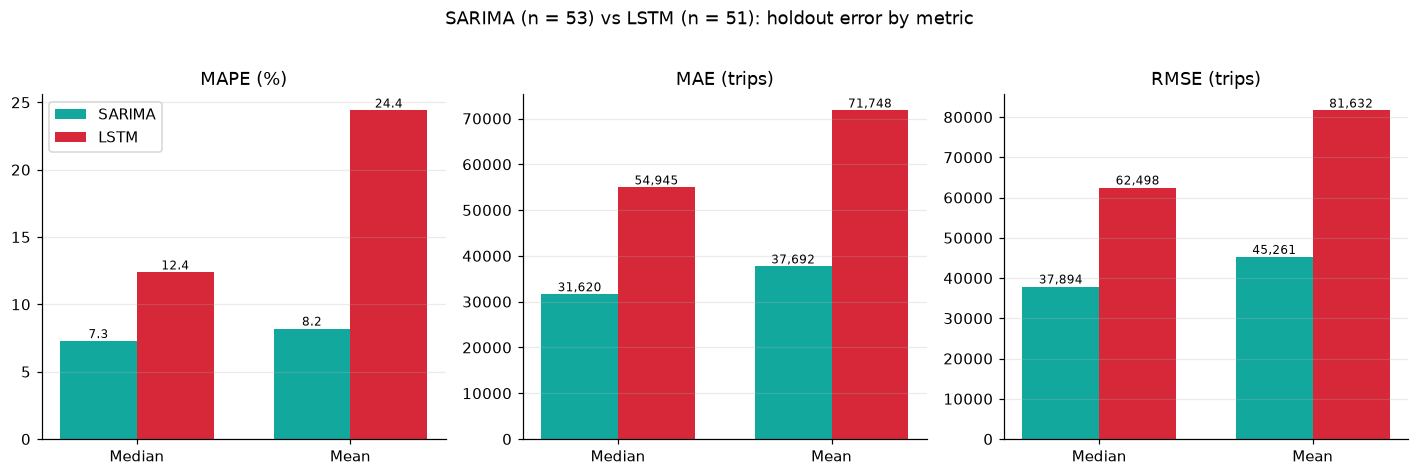

In [30]:
panels = [("MAPE (%)", "MAPE_sarima", "MAPE_lstm"), ("MAE (trips)", "MAE_sarima", "MAE_lstm"), ("RMSE (trips)", "RMSE_sarima", "RMSE_lstm")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (title, cs, cl) in zip(axes, panels):
    vals = {"SARIMA": [comp[cs].median(), comp[cs].mean()], "LSTM": [comp[cl].median(), comp[cl].mean()]}
    x = np.arange(2); w = .36
    for i, (m_, col) in enumerate([("SARIMA", TEAL), ("LSTM", RED)]):
        bars = ax.bar(x + (i - .5) * w, vals[m_], w, color=col, label=m_)
        for b_, v in zip(bars, vals[m_]): ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v:,.1f}" if "%" in title else f"{v:,.0f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(["Median", "Mean"]); ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].legend()
fig.suptitle("SARIMA (n = 53) vs LSTM (n = 51): holdout error by metric", y=1.02); fig.tight_layout()
save_fig(fig, "Figure 6.1", "grouped_bar_metrics")

### Figure 6.2 - Paired difference in MAPE per station


saved ..\docs\testing\figures\Figure_6.2_paired_difference.png


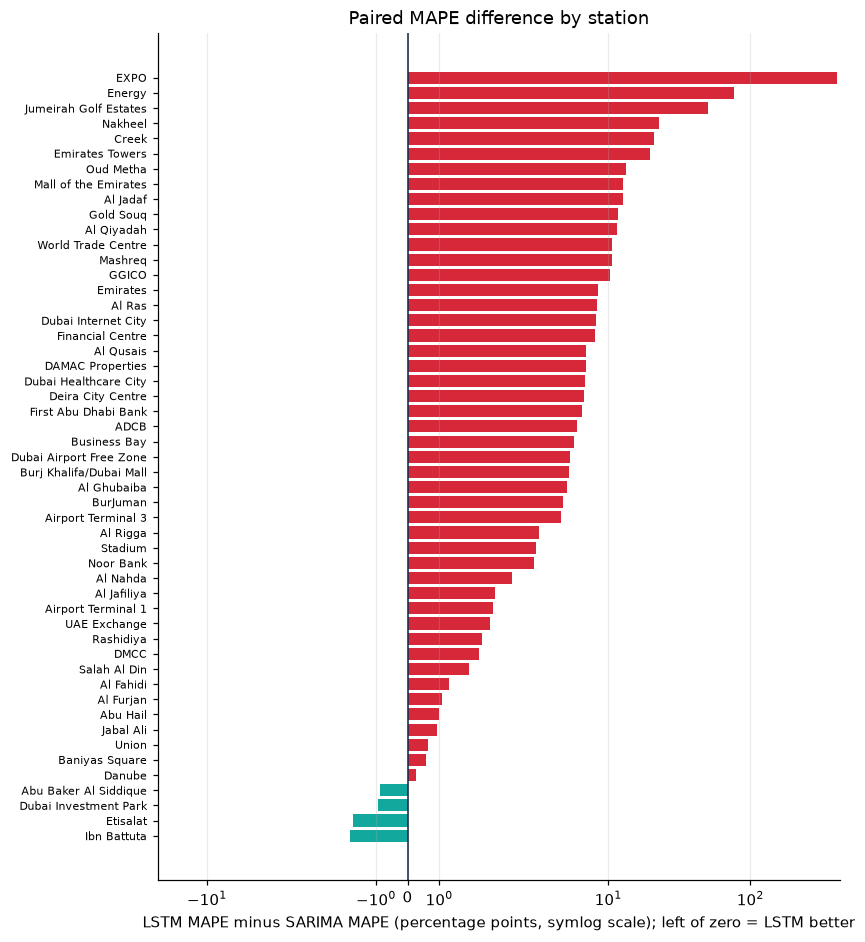

In [31]:
d = both.assign(diff=both.MAPE_lstm - both.MAPE_sarima).sort_values("diff")
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh([s.replace(" Metro Station", "") for s in d.station], d["diff"], color=[TEAL if v < 0 else RED for v in d["diff"]])
ax.axvline(0, c=NAVY, lw=1); ax.set_xscale("symlog", linthresh=5); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7)
ax.set(xlabel="LSTM MAPE minus SARIMA MAPE (percentage points, symlog scale); left of zero = LSTM better",
       title="Paired MAPE difference by station")
save_fig(fig, "Figure 6.2", "paired_difference")

In [32]:
# Appendix - per-station results (all 53 stations)
appH = comp[["station","MAPE_sarima","RMSE_sarima","MAE_sarima","MAPE_lstm","RMSE_lstm","MAE_lstm","winner"]].copy()
appH["station"] = appH.station.str.replace(" Metro Station", "", regex=False)
appH = appH.sort_values("MAPE_sarima").round(2); save_table(appH, "Table A.2", "per_station_results"); appH.head()

saved Table_A.2_per_station_results


,station,MAPE_sarima,RMSE_sarima,MAE_sarima,MAPE_lstm,RMSE_lstm,MAE_lstm,winner
37,Gold Souq,4.49,23246.10,18358.67,16.16,73060.63,62521.30,SARIMA
19,Creek,4.62,6744.86,5282.43,25.75,30644.63,28475.91,SARIMA
16,BurJuman,4.76,113388.46,81108.08,9.69,177182.51,153575.48,SARIMA
9,Al Jafiliya,5.16,29235.39,23697.20,7.93,40380.34,36191.60,SARIMA
15,Baniyas Square,5.19,56515.81,48018.40,5.76,62497.99,52032.57,SARIMA


## Section C - Dashboard tests (Table 6.3), browser checks and Figure 6.3


In [33]:
func = pd.DataFrame([
 ["F01", "FR1", "Open Explorer. Count and inspect map markers.", "All 53 stations drawn, coloured by line", "BurJuman"],
 ["F02", "FR2", "Select BurJuman by clicking the map, then select Etisalat from the dropdown.", "Stat cards and chart update both ways; selected station highlighted", "BurJuman, Etisalat"],
 ["F03", "FR3", "Read the history shown for BurJuman.", "Series runs Jan 2018 - Aug 2023 (68 months)", "BurJuman"],
 ["F04", "FR4", "Set horizon slider to 1, 6 and 12.", "Forecast length and the label (in months) match each setting", "BurJuman"],
 ["F05", "FR5", "Toggle SARIMA to LSTM at BurJuman; open Discovery Gardens.", "Forecast changes; LSTM option disabled at Discovery Gardens", "BurJuman, Discovery Gardens"],
 ["F06", "FR6", "Show SARIMA forecast for BurJuman.", "Shaded confidence interval visible around the forecast", "BurJuman"],
 ["F07", "FR7", "Open BurJuman, then Etisalat.", "Badge matches holdout MAPE: BurJuman -> SARIMA (4.8 vs LSTM higher); Etisalat -> LSTM (6.14 vs 7.87)", "BurJuman, Etisalat"],
 ["F08", "FR8", "Open Comparison. Sort table by MAPE; page through.", "53 rows paginated and sortable; 4 LSTM wins highlighted", "-"],
 ["F09", "FR9", "Open Insights.", "System trend with COVID shading, normalised seasonality, EXPO / Route 2020 / World Trade Centre callouts", "-"],
 ["F10", "FR10", "Read the MAPE box plot on Comparison.", "Median markers agree with Table 5.10 (7.27% and 12.37%)", "-"],
], columns=["ID", "Requirement", "Procedure", "Expected result", "Station(s)"])
func["Result"] = "Not yet run"; func["Evidence"] = ""
def mark_f(fid, result, note=""):
    assert result in ("Pass", "FAIL", "Not yet run"); func.loc[func.ID == fid, ["Result", "Evidence"]] = [result, note]
# mark_f("F01", "Pass", "53 markers visible (F01.png)")
save_table(func[["ID", "Requirement", "Procedure", "Expected result", "Result"]], "Table 6.3", "dashboard_functional_tests")
print(func.Result.value_counts().to_string()); func[["ID", "Requirement", "Result"]]

saved Table_6.3_dashboard_functional_tests
Result
Not yet run    10


,ID,Requirement,Result
0,F01,FR1,Not yet run
1,F02,FR2,Not yet run
2,F03,FR3,Not yet run
3,F04,FR4,Not yet run
4,F05,FR5,Not yet run
5,F06,FR6,Not yet run
6,F07,FR7,Not yet run
7,F08,FR8,Not yet run
8,F09,FR9,Not yet run
9,F10,FR10,Not yet run


In [34]:
func.loc[func.ID == "F02", "Station(s)"] = "BurJuman, Deira City Centre, Energy"
func.loc[func.ID == "F07", "Expected result"] = "BurJuman (SARIMA): 'SARIMA recommended (4.8% vs 9.7% MAPE)'; Etisalat (SARIMA): 'Showing SARIMA - LSTM performs better here (7.9% vs 6.1% MAPE)'; Etisalat (LSTM): 'LSTM recommended (7.9% vs 6.1% MAPE)'"
func.loc[func.ID == "F08", "Expected result"] = "Stations-won card SARIMA 49 · LSTM 4 (47 head-to-head plus 2 stations without an LSTM); 53 rows over 4 pages (15+15+15+8), sortable; four LSTM-win rows shaded"
func.loc[func.ID == "F09", "Expected result"] = "System trend with COVID shading; seasonal chart with '~21% swing - Mar peak, Sep trough'; EXPO, Route 2020 and World Trade Centre (SARIMA 10.7%, LSTM 21.3%) callouts"
func.loc[func.ID == "F10", "Expected result"] = "Cards 7.27% and 12.37%; box-plot medians 7.274 and 12.371 (matches Table 5.10)"

mark_f("F01", "Pass", "Console count of map markers = 53 (F01.png); markers coloured by line. The 'Total stations' card is hard-coded, so the marker count is the evidence.")
mark_f("F02", "Pass", "Map click on Deira City Centre updates dropdown, highlight and chart (F02.png); dropdown selection of Energy moves the highlight and updates chart and badge (F02_2.png).")
mark_f("F03", "Pass", "BurJuman history runs from Jan 2018 (1,100,941) to Aug 2023 (1,569,292) (F03_1.png, F03_2.png).")
mark_f("F04", "Pass", "Horizon 1, 6, 12: labels '1 month', '6 months', '12 months'; 1, 6 and 12 forecast points; single point drawn with error bar (F04_1-3.png).")
mark_f("F05", "Pass", "BurJuman: LSTM forecast with banner 'Showing LSTM - SARIMA performs better (4.8% vs 9.7%)' (F05_1.png). Discovery Gardens: LSTM greyed out, SARIMA shown with 'insufficient history' banner (F05_2.png).")
mark_f("F06", "Pass", "SARIMA at BurJuman shows shaded 95% interval (F06_1.png); LSTM view shows none, as designed (F06_2.png).")
mark_f("F07", "Pass", "BurJuman SARIMA recommended 4.8% vs 9.7% (F07_1.png); Etisalat on SARIMA: 'LSTM performs better here' 7.9% vs 6.1% (F07_2.png); Etisalat on LSTM: 'LSTM recommended' (F07_3.png).")
mark_f("F08", "Pass", "Four pages of 15, 15, 15, 8 rows = 53; sortable; four LSTM wins shaded; stations without an LSTM show a blank cell and SARIMA. Card reads SARIMA 49 / LSTM 4 (47 + 2 default) (F08_1-4.png).")
mark_f("F09", "Pass", "Trend with COVID shading, seasonal chart with '~21% swing - Mar peak, Sep trough', three callouts; World Trade Centre 10.7% / 21.3% agrees with the comparison table (F09.png).")
mark_f("F10", "Pass", "Median cards 7.27% and 12.37%; box-plot hover medians 7.274 and 12.371 (F10_1.png, F10_2.png); y-axis zoomed to read them.")

table63 = save_table(func[["ID", "Requirement", "Procedure", "Expected result", "Result"]], "Table 6.3", "dashboard_functional_tests")
print(func.Result.value_counts())

saved Table_6.3_dashboard_functional_tests
Result
Pass    10
Name: count, dtype: int64


In [35]:
print(func[["ID", "Result"]])

    ID Result
0  F01   Pass
1  F02   Pass
2  F03   Pass
3  F04   Pass
4  F05   Pass
5  F06   Pass
6  F07   Pass
7  F08   Pass
8  F09   Pass
9  F10   Pass


### Figure 6.3 - Screenshot evidence montage


F02 (FR2): Pass
F05_1 (FR5): Pass
F07_3 (FR7): Pass
F08_1 (FR8): Pass
F09 (FR9): Pass
F10_2 (FR10): Pass
saved ..\docs\testing\figures\Figure_6.3_screenshot_evidence.png


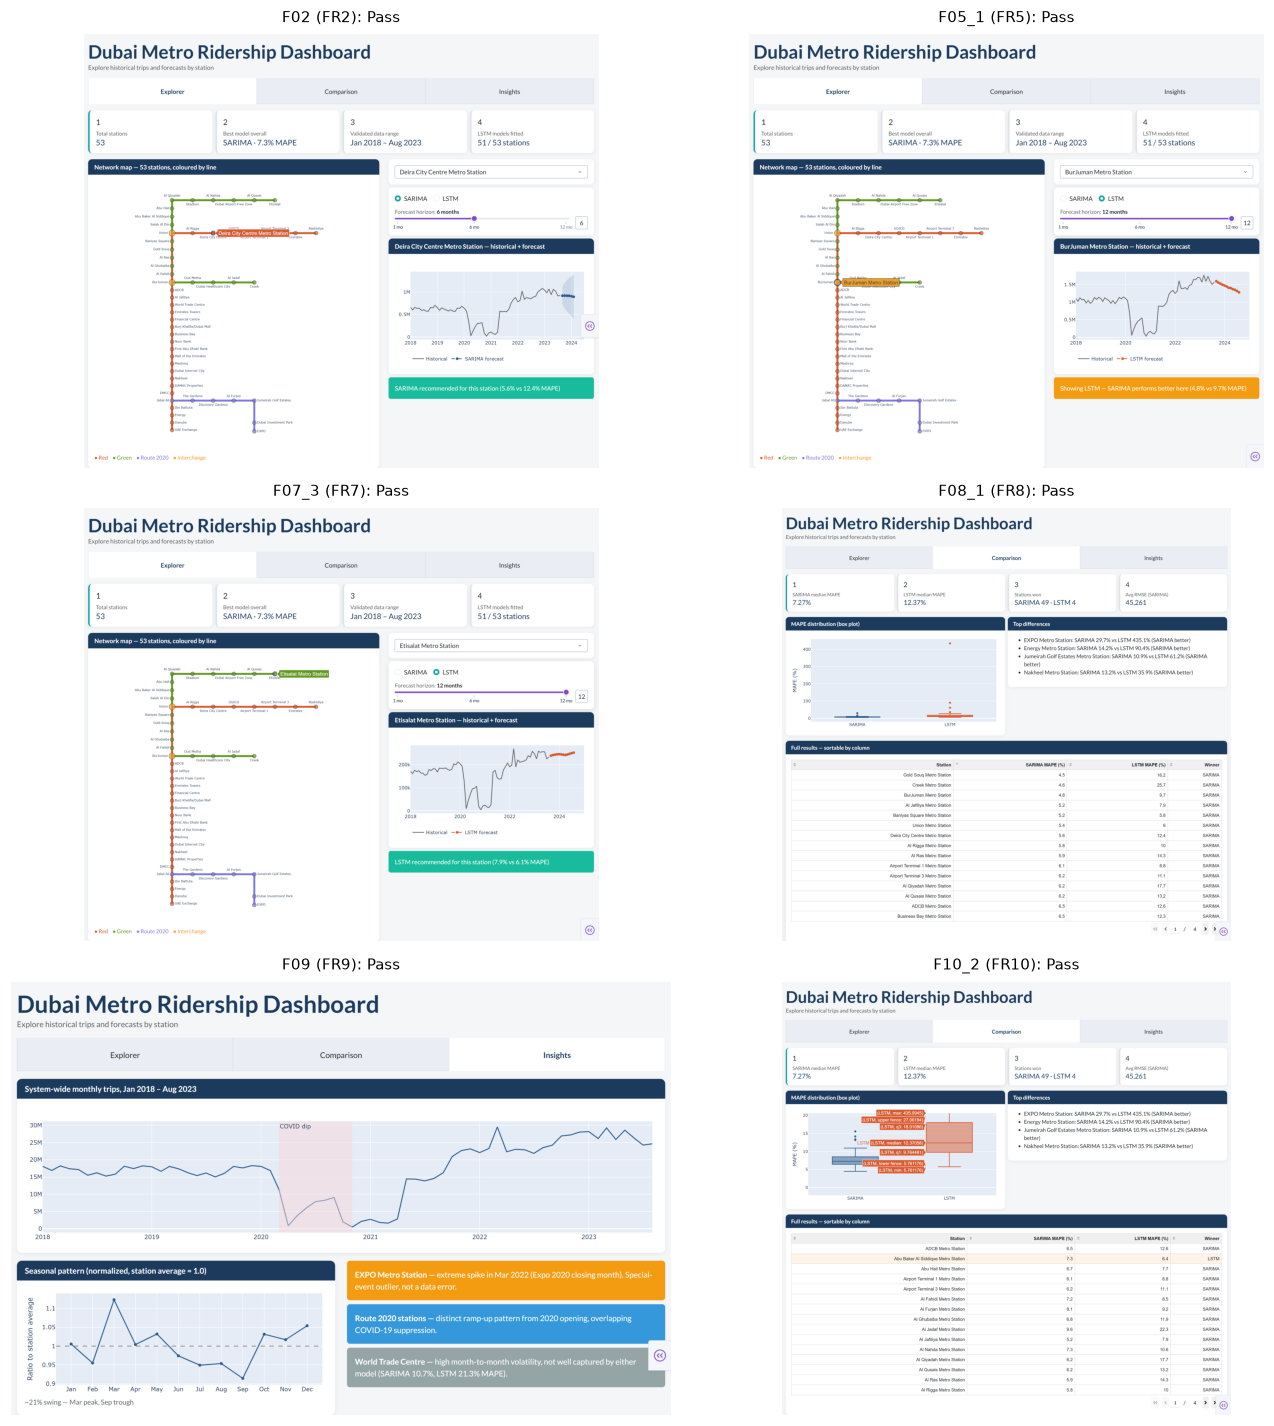

In [36]:
def montage(ids, cols=2, label="Figure 6.3", slug="screenshot_evidence"):
    have = [i for i in ids if (SHOTS/f"{i}.png").exists()]
    missing = [i for i in ids if i not in have]
    if missing: print("Missing screenshots:", missing)
    if not have: print("No screenshots found in", SHOTS); return
    rows = int(np.ceil(len(have) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6.5 * cols, 4.4 * rows)); axes = np.atleast_1d(axes).ravel()
    fig.patch.set_facecolor("white")
    lookup = {**{r.ID: (r.Requirement, r.Result) for r in func.itertuples()},
              **{r.ID: (r.Requirement, r.Result) for r in manual.itertuples()}}
    for ax, i in zip(axes, have):
        req, res = lookup.get(i.split("_")[0], ("", ""))      # "F05_1" -> "F05", "T14_explorer" -> "T14"
        title = f"{i} ({req}): {res}"; print(title)
        ax.imshow(plt.imread(SHOTS/f"{i}.png")); ax.axis("off")
        ax.set_title(title, fontsize=10, color="black", pad=8)
    for ax in axes[len(have):]: ax.axis("off")
    fig.tight_layout(rect=(0, 0, 1, 0.99)); save_fig(fig, label, slug)
montage(["F02", "F05_1", "F07_3", "F08_1", "F09", "F10_2"])    # use the filenames you actually have

## Section D - Defect log (Table 6.4)
18 defects: 4 environmental, 5 data, 2 modelling, 7 dashboard. 

In [37]:
bugs = pd.DataFrame([
 ["D01", "Environment", "Virtual environment unusable after project folder renamed", "Absolute path stored in pip.exe", "Deleted; rebuilt venv in the final folder", "Never rename or move the project folder after creating the venv"],
 ["D02", "Environment", "Incomplete virtual environment (no Activate.ps1)", "Interrupted build", "Deleted and recreated", "Confirm the activation script exists after building"],
 ["D03", "Environment", "Git not installed at project start", "Tool not installed", "Installed Git; initialised version control", "Check tools before starting"],
 ["D11", "Environment", "Notebook kernel showed NameError and froze after the LSTM run", "Resource contention after a long run", "Restarted kernel; Run All", "Restart the kernel before long runs"],
 ["D04", "Data", "FileNotFoundError reading the raw CSV", "Filename contained dashes; notebook folder needed ../", "Listed the folder with os.listdir and used the exact name", "List or glob files; never retype names"],
 ["D05", "Data", "Diagonal artefact in DMCC, Gold Souq, Jabal Ali and Mashreq plots", "Rows unsorted after the rename merge", "Re-sorted by station and date; master and model-ready files re-saved", "Sort after every merge (test T01)"],
 ["D06", "Data", "Burj Khalifa/Dubai Mall mismatched at three stages: raw label, missing line and coordinates, results key; win counts 46/5/3 instead of 47/4/2", "Stray space in the label defeated exact-name merges", "Normalised label; restored fields; re-ran station; re-merged results", "Verify keys and row counts after every merge (test T03)"],
 ["D07", "Data", "Geocoding failed for about 75% of station names", "Nominatim could not resolve the names", "Switched to OpenStreetMap Overpass; 14 names mapped manually", "Check match rate before relying on a geocoder"],
 ["D08", "Data", "Reported trips collapsed about 23 times from May 2024; Sep-Dec 2023 unusable", "Change in the source's data collection or aggregation", "Validated against RTA statistics; restricted window to Jan 2018 - Aug 2023", "Validate source data against an external reference"],
 ["D09", "Modelling", "Exhaustive SARIMA search failed at 7 stations", "NaN gaps in series; AIC candidates lacked diversity", "Linear interpolation; union of fixed and AIC candidates", "Handle gaps before fitting"],
 ["D10", "Modelling", "LSTM accuracy varied between runs (BurJuman 9.0% to 25.1%)", "Few sequences and random initialisation", "Averaged predictions over three runs", "Average runs; report spread"],
 ["D12", "Dashboard", "App printed 'Loaded...' then hung", "Reloader subprocess failed on a path containing a space; app.run guard missing", "use_reloader=False; added __main__ guard", "Avoid spaces in project paths"],
 ["D13", "Dashboard", "0 models loaded at start-up", "../ prefix although the app runs from the project root", "Removed ../ from model and CSV paths", "Build paths from the app's own location"],
 ["D14", "Dashboard", "'ID not found in layout' banner", "Tab callback creates targets dynamically", "suppress_callback_exceptions = True", "Know which components are created dynamically"],
 ["D15", "Dashboard", "Two model toggles on screen, one dead", "Four stale python.exe processes serving old code (reloader off)", "Killed all python.exe; restarted from a fresh terminal", "Restart after every edit; check Task Manager"],
 ["D16", "Dashboard", "Map labels clipped and overlapped; EXPO branch drawn diagonally; Al Fahidi and BurJuman at identical coordinates; uneven Green Line spacing", "Default label positions, margins and initial coordinates", "Per-station label sides; wider margin with cliponaxis=False; explicit right-angle bend; corrected schematic_positions.json", "Set layout explicitly; inspect all stations"],
 ["D17", "Dashboard", "Station labels overlapped on the Green, Red, BurJuman and Route 2020 rows at 1280 px (found by T15)", "All labels in a horizontal run placed on the same side of the line", "Alternated top/bottom label positions along each run; moved DMCC to the left of the trunk", "Inspect every row of the map at the target width after any layout change"],
 ["D18", "Dashboard", "Forecast not visible at horizon 1; confidence interval drawn as stray markers (found by T16)", "Single-point forecast trace drawn with mode='lines'; interval trace used default markers", "Forecast traces use lines+markers; interval shown as error bars at horizon 1 and as a band otherwise", "Check horizon limits visually as well as by length (T06 only checked the number of values)"],
], columns=["ID", "Stage", "Defect", "Root cause", "Resolution", "Preventive control"]).sort_values("ID").reset_index(drop=True)
print(bugs.Stage.value_counts().to_string())
assert bugs.Stage.value_counts().to_dict() == {"Dashboard": 7, "Data": 5, "Environment": 4, "Modelling": 2}, "counts must match the chapter text (4/5/2/7)"
save_table(bugs, "Table 6.4", "defect_log"); bugs[["ID", "Stage", "Defect"]]

Stage
Dashboard      7
Data           5
Environment    4
Modelling      2
saved Table_6.4_defect_log


,ID,Stage,Defect
0,D01,Environment,Virtual environment unusable after project fol...
1,D02,Environment,Incomplete virtual environment (no Activate.ps1)
2,D03,Environment,Git not installed at project start
3,D04,Data,FileNotFoundError reading the raw CSV
4,D05,Data,"Diagonal artefact in DMCC, Gold Souq, Jabal Al..."
5,D06,Data,Burj Khalifa/Dubai Mall mismatched at three st...
6,D07,Data,Geocoding failed for about 75% of station names
7,D08,Data,Reported trips collapsed about 23 times from M...
8,D09,Modelling,Exhaustive SARIMA search failed at 7 stations
9,D10,Modelling,LSTM accuracy varied between runs (BurJuman 9....
